# Predicting final midprice from Optiver data - Swarnendu
1. In Google Drive, add a shortcut of the shared `Optiver_Project` folder to **My Drive**. Keep the same folder name.
2. Run setup cells **1–3** and allow Drive access. The data is already saved; no Kaggle download is needed.
3. Add your exploration and visualizations under your name below.

Rerun setup when starting a new Colab session.

## 1. Connect Google Drive

In [1]:
from pathlib import Path
import os
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pyarrow
from google.colab import drive
from IPython.display import display

drive.mount("/content/drive")
DATA_DIR = Path("/content/drive/MyDrive/Optiver_Project/data")
LOCAL_DIR = Path("/content/optiver_data")


Mounted at /content/drive


## 2. Access the saved data

In [2]:
def data_complete(folder):
    """Check labels, stock partitions, and the supplied test files."""
    try:
        if not all((folder / name).is_file() for name in
                   ["train.csv", "test.csv", "sample_submission.csv"]):
            return False
        labels = pd.read_csv(folder / "train.csv", usecols=["stock_id"])
        if labels.empty:
            return False
        for kind in ["book", "trade"]:
            for stock_id in labels.stock_id.unique():
                part = folder / f"{kind}_train.parquet" / f"stock_id={stock_id}"
                if not any(p.stat().st_size > 0 for p in part.rglob("*.parquet")):
                    return False
            if not any(p.stat().st_size > 0 for p in
                       (folder / f"{kind}_test.parquet").rglob("*.parquet")):
                return False
        return True
    except (OSError, ValueError, pd.errors.EmptyDataError):
        return False

if data_complete(DATA_DIR):
    print("Using the existing Google Drive copy. No download needed.")
else:
    if not data_complete(LOCAL_DIR):
        print("No complete saved copy found. Downloading from Kaggle once...")
        import kagglehub
        from google.colab import userdata
        try:
            os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")
        except Exception:
            raise RuntimeError(
                "Add KAGGLE_API_TOKEN in Colab Secrets and enable notebook access. "
                "Teammates: first check that the shared Drive shortcut and DATA_DIR are correct."
            ) from None
        kagglehub.competition_download(
            "optiver-realized-volatility-prediction", output_dir=str(LOCAL_DIR)
        )
        if not data_complete(LOCAL_DIR):
            raise RuntimeError("The local download is incomplete. Check the download output.")
    print("Copying the downloaded files to Google Drive. Wait for completion...")
    DATA_DIR.parent.mkdir(parents=True, exist_ok=True)
    shutil.copytree(LOCAL_DIR, DATA_DIR, dirs_exist_ok=True)
    if not data_complete(DATA_DIR):
        raise RuntimeError("The Drive copy is incomplete. Check available Drive space and rerun.")

print("Data saved in Google Drive and ready:", DATA_DIR)

Using the existing Google Drive copy. No download needed.
Data saved in Google Drive and ready: /content/drive/MyDrive/Optiver_Project/data


## 3. Load data
`train` = all labels; `book` and `trades` = one stock. Change `STOCK_ID` to explore another stock.

In [3]:
train = pd.read_csv(DATA_DIR / "train.csv")
STOCK_ID = 0  # Change this to another stock_id from train.

def load_stock(kind, stock_id):
    folder = DATA_DIR / f"{kind}_train.parquet" / f"stock_id={stock_id}"
    paths = sorted(folder.rglob("*.parquet"))
    if not paths:
        raise ValueError(f"No {kind} data found for stock_id={stock_id}.")
    return pd.concat([pd.read_parquet(p) for p in paths], ignore_index=True).sort_values(
        ["time_id", "seconds_in_bucket"]
    ).reset_index(drop=True)

book = load_stock("book", STOCK_ID)
trades = load_stock("trade", STOCK_ID)
print(f"Labels: {len(train):,} | Stocks: {train.stock_id.nunique()}")
print(f"Stock {STOCK_ID}: {len(book):,} book rows; {len(trades):,} trade rows")
display(train.head())
display(book.head())
display(trades.head())


Labels: 428,932 | Stocks: 112
Stock 0: 917,553 book rows; 123,443 trade rows


,stock_id,time_id,target
0,0,5,0.004136
1,0,11,0.001445
2,0,16,0.002168
3,0,31,0.002195
4,0,62,0.001747


,time_id,seconds_in_bucket,bid_price1,ask_price1,bid_price2,ask_price2,bid_size1,ask_size1,bid_size2,ask_size2
0,5,0,1.001422,1.002301,1.00137,1.002353,3,226,2,100
1,5,1,1.001422,1.002301,1.00137,1.002353,3,100,2,100
2,5,5,1.001422,1.002301,1.00137,1.002405,3,100,2,100
3,5,6,1.001422,1.002301,1.00137,1.002405,3,126,2,100
4,5,7,1.001422,1.002301,1.00137,1.002405,3,126,2,100


,time_id,seconds_in_bucket,price,size,order_count
0,5,21,1.002301,326,12
1,5,46,1.002778,128,4
2,5,50,1.002818,55,1
3,5,57,1.003155,121,5
4,5,68,1.003646,4,1


## Exploring the Training Data and Stock Coverage

# Stock ID Availability Check

Checks whether the order-book (`book_train.parquet`) and trade (`trade_train.parquet`) folders contain data for the same stocks.

The code:
- Extracts stock IDs from folder names.
- Counts the number of stocks in each dataset.
- Compares the two sets of stock IDs.
- Identifies missing stock IDs and lists all available stocks.

**Note:** Uses folder names only; no Parquet files or `train.csv` are loaded.

In [28]:
# Identify stock IDs in the order-book folder
book_root = DATA_DIR / "book_train.parquet"

book_st_id = [
    int(folder.name.split("=")[1])
    for folder in book_root.glob("stock_id=*")
    if folder.is_dir()
]

# Identify stock IDs in the trade folder
trade_root = DATA_DIR / "trade_train.parquet"

trade_st_id = [
    int(folder.name.split("=")[1])
    for folder in trade_root.glob("stock_id=*")
    if folder.is_dir()
]

# Convert to sets
book_id = set(book_st_id)
trade_id = set(trade_st_id)

# Compare stock IDs
print("Number of stock IDs in book folder:", len(book_id))
print("Number of stock IDs in trade folder:", len(trade_id))

print("\nDo both folders contain the same stock IDs?", book_id == trade_id)

print("\nStock IDs only in book folder:", sorted(book_id - trade_id))
print("Stock IDs only in trade folder:", sorted(trade_id - book_id))

# List all available stock IDs
print("\nAvailable stock IDs:", sorted(book_id))

Number of stock IDs in book folder: 112
Number of stock IDs in trade folder: 112

Do both folders contain the same stock IDs? True

Stock IDs only in book folder: []
Stock IDs only in trade folder: []

Available stock IDs: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 46, 47, 48, 50, 51, 52, 53, 55, 56, 58, 59, 60, 61, 62, 63, 64, 66, 67, 68, 69, 70, 72, 73, 74, 75, 76, 77, 78, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 93, 94, 95, 96, 97, 98, 99, 100, 101, 102, 103, 104, 105, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 118, 119, 120, 122, 123, 124, 125, 126]


## Defining the Target: Relative Mid-Price Change

The objective is to predict the relative change in mid-price over the final minute of each 10-minute observation window, using order-book and trade information available up to 300 seconds (5 minutes).

The mid-price is defined as the average of the best ask price and the best bid price:

$m_t = \frac{\text{ask price}_t + \text{bid price}_t}{2}.$

For each `time_id`, we calculate two prices:

- **Starting mid-price $(m_{300})$**: the last available mid-price at or before 300 seconds.
- **Final mid-price $(m_{\mathrm{last}}$)**: the last available mid-price at 600 seconds.

The target variable is the last mid-price:

$\text{target} = m_{\mathrm{last}}$



In [5]:
def calculate_target_midprices(g):
    t = g["seconds_in_bucket"].to_numpy()
    p = g["MidPrice"].to_numpy()

    # Last mid-price at or before 540 seconds
    i300 = np.searchsorted(t, 300, side="right") - 1

    # Last available mid-price at or before 600 seconds
    iend = np.searchsorted(t, 600, side="right") - 1

    # Require a starting price and a final-minute observation
    if i300 < 0 or iend < 0 or t[iend] <= 300:
      return pd.Series({"midprice_300": np.nan, "midprice_last": np.nan, "midprice_relchange": np.nan})

    m300 = p[i300]
    mend = p[iend]

    if m300 <= 0 or mend <= 0:
      return pd.Series({"midprice_300": m300, "midprice_last": mend, "midprice_relchange": np.nan})

    return pd.Series({"midprice_300": m300, "midprice_last": mend, "midprice_relchange": (mend - m300) / m300})

def engineer_target(st_id, diagnostics=False):

    # Load order-book data for one stock
    df = load_stock("book", st_id).copy()

    # Sort snapshots within each time window
    df = df.sort_values(["time_id", "seconds_in_bucket"]).copy()

    df["MidPrice"] = (df["ask_price1"] + df["bid_price1"]) / 2

    targets = (df.groupby("time_id").apply(calculate_target_midprices, include_groups=False).reset_index())
    targets["stock_id"] = st_id
    targets = targets[["stock_id", "time_id", "midprice_300", "midprice_last", "midprice_relchange"]]


    if diagnostics:
        print(f"Stock ID: {st_id}")
        print("Book shape:", df.shape)
        print("Number of time IDs:", df["time_id"].nunique())
        print("Missing values:\n", df.isnull().sum())

    return targets

stock_ids=np.sort(book_st_id)
all_targets=[]

for st_id in stock_ids:
    print(f"Processing stock {st_id}")
    targets = engineer_target(st_id=st_id, diagnostics=False)
    all_targets.append(targets)

Y = pd.concat(all_targets, ignore_index=True)

print("Target matrix shape:", Y.shape)
print("Number of stocks:", Y["stock_id"].nunique())
print("Number of stock/time_id rows:", Y[["stock_id", "time_id"]].drop_duplicates().shape[0])

display(Y.head())

Processing stock 0
Processing stock 1
Processing stock 2
Processing stock 3
Processing stock 4
Processing stock 5
Processing stock 6
Processing stock 7
Processing stock 8
Processing stock 9
Processing stock 10
Processing stock 11
Processing stock 13
Processing stock 14
Processing stock 15
Processing stock 16
Processing stock 17
Processing stock 18
Processing stock 19
Processing stock 20
Processing stock 21
Processing stock 22
Processing stock 23
Processing stock 26
Processing stock 27
Processing stock 28
Processing stock 29
Processing stock 30
Processing stock 31
Processing stock 32
Processing stock 33
Processing stock 34
Processing stock 35
Processing stock 36
Processing stock 37
Processing stock 38
Processing stock 39
Processing stock 40
Processing stock 41
Processing stock 42
Processing stock 43
Processing stock 44
Processing stock 46
Processing stock 47
Processing stock 48
Processing stock 50
Processing stock 51
Processing stock 52
Processing stock 53
Processing stock 55
Processing

,stock_id,time_id,midprice_300,midprice_last,midprice_relchange
0,0,5,1.004137,1.003439,-0.000695
1,0,11,1.000276,1.000527,0.000251
2,0,16,0.999952,0.997798,-0.002154
3,0,31,0.998381,0.997941,-0.000440
4,0,62,0.999534,0.999930,0.000396


# Order Book and Trade Activity Visualization

Visualize order-book and trade data for a selected stock and `time_id` over a 10-minute window using Python, Pandas, and Matplotlib.

## Data

**Order-book data:** Best and second-best bid/ask prices and sizes (`bid_price1`, `ask_price1`, `bid_size1`, `ask_size1`, etc.).

**Trade data:** Executed price, trade size, and order count.

**Mid-price**:$=\frac{\text{ask_price1}+\text{bid_price1}}{2} $

## Visualization

The figure contains three panels:

1. **Price dynamics:** Bid/ask prices at Levels 1 and 2, mid-price, trade prices, and final observed mid-price.
2. **Order-book depth:** Bid and ask sizes at the first two price levels.
3. **Trade activity:** Trade size and order count.

The vertical line at 300 seconds marks the prediction cutoff.

- **0–300 seconds:** Model input period.
- **300–600 seconds:** Prediction horizon.
- **Final observed mid-price:** Forecasting target.



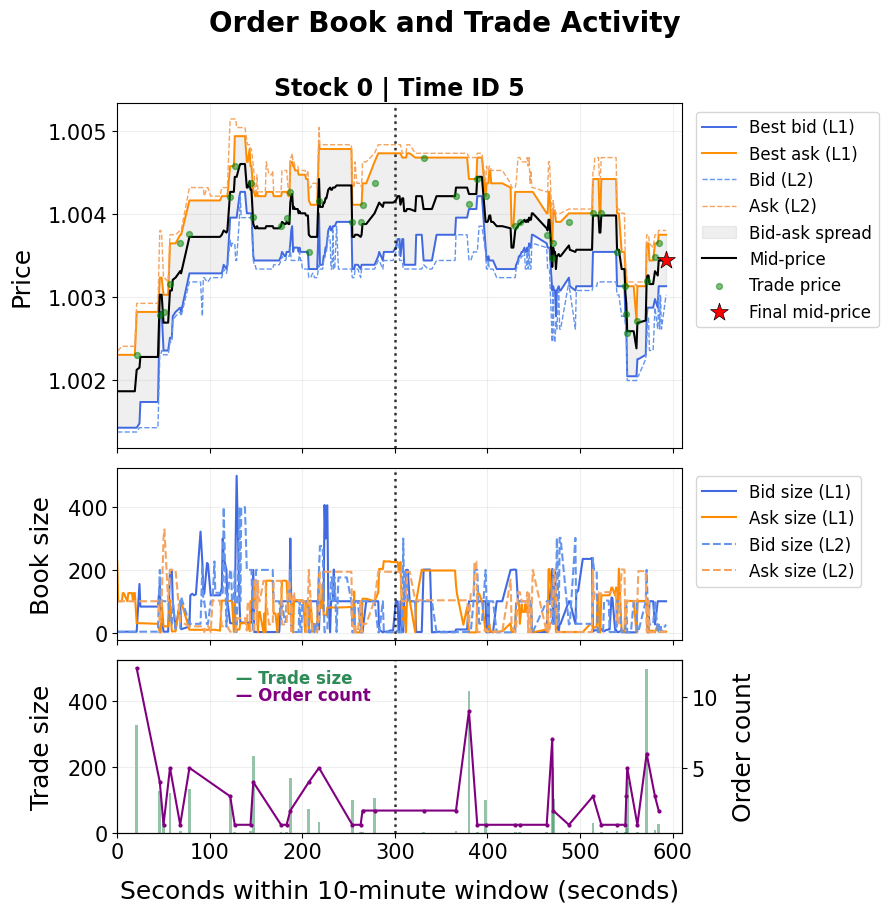

In [6]:


# ==========================================
# 1. LOAD AND PREPARE DATA
# ==========================================

st_id = 0
tid = 5

book = load_stock("book", st_id).copy()
trade = load_stock("trade", st_id).copy()

# Select the required time_id
book = book[book["time_id"] == tid].copy()
trade = trade[trade["time_id"] == tid].copy()

# Sort observations by time
book = book.sort_values("seconds_in_bucket").reset_index(drop=True)
trade = trade.sort_values("seconds_in_bucket").reset_index(drop=True)

# Keep observations up to 600 seconds
book = book[book["seconds_in_bucket"] <= 600].copy()
trade = trade[trade["seconds_in_bucket"] <= 600].copy()

# Calculate mid-price
book["MidPrice"] = (book["ask_price1"] + book["bid_price1"]) / 2

# Check whether order-book data exist
if book.empty:
    raise ValueError(f"No order-book data for stock {st_id}, time_id {tid}")

# Final observed mid-price
final_price = book["MidPrice"].iloc[-1]
final_time = book["seconds_in_bucket"].iloc[-1]

# ==========================================
# 2. CREATE FIGURE
# ==========================================

fig, axes = plt.subplots(
    3, 1,
    figsize=(9, 9),
    sharex=True,
    gridspec_kw={"height_ratios": [3, 1.5, 1.5]}
)

ax1, ax2, ax3 = axes
t = book["seconds_in_bucket"]

# ==========================================
# 3. PRICE PANEL
# ==========================================

ax1.plot(t, book["bid_price1"], color="royalblue",
         linewidth=1.4, label="Best bid (L1)")

ax1.plot(t, book["ask_price1"], color="darkorange",
         linewidth=1.4, label="Best ask (L1)")

ax1.plot(t, book["bid_price2"], color="cornflowerblue",
         linestyle="--", linewidth=1, label="Bid (L2)")

ax1.plot(t, book["ask_price2"], color="sandybrown",
         linestyle="--", linewidth=1, label="Ask (L2)")

ax1.fill_between(
    t,
    book["bid_price1"],
    book["ask_price1"],
    color="grey",
    alpha=0.12,
    label="Bid-ask spread"
)

ax1.plot(t, book["MidPrice"], color="black",
         linewidth=1.5, label="Mid-price")

if not trade.empty and "price" in trade.columns:
    ax1.scatter(
        trade["seconds_in_bucket"],
        trade["price"],
        color="green",
        s=18,
        alpha=0.5,
        label="Trade price",
        zorder=4
    )

# Mark the final observed mid-price
ax1.scatter(
    final_time,
    final_price,
    color="red",
    marker="*",
    s=180,
    edgecolors="black",
    linewidths=0.5,
    label="Final mid-price",
    zorder=6
)

ax1.set_ylabel("Price", fontsize=18, labelpad=10)
ax1.set_title(
    f"Stock {st_id} | Time ID {tid}",
    fontsize=17,
    fontweight="bold"
)

ax1.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=12)
ax1.grid(alpha=0.2)

# ==========================================
# 4. ORDER-BOOK SIZE PANEL
# ==========================================

ax2.plot(t, book["bid_size1"], color="royalblue",
         label="Bid size (L1)")

ax2.plot(t, book["ask_size1"], color="darkorange",
         label="Ask size (L1)")

ax2.plot(t, book["bid_size2"], color="cornflowerblue",
         linestyle="--", label="Bid size (L2)")

ax2.plot(t, book["ask_size2"], color="sandybrown",
         linestyle="--", label="Ask size (L2)")

ax2.set_ylabel("Book size", fontsize=18, labelpad=10)
ax2.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=12)
ax2.grid(alpha=0.2)

# ==========================================
# 5. TRADE ACTIVITY PANEL
# ==========================================

if not trade.empty:

    ax3.bar(
        trade["seconds_in_bucket"],
        trade["size"],
        width=3.0,          # thicker bars
        color="seagreen",
        alpha=0.5,
        label="Trade size"
    )

    ax3.set_ylabel("Trade size", fontsize=18, labelpad=10)

    # Secondary y-axis for order count
    if "order_count" in trade.columns:

        ax3b = ax3.twinx()

        ax3b.plot(
            trade["seconds_in_bucket"],
            trade["order_count"],
            color="purple",
            marker=".",
            markersize=4,
            linewidth=1.5,
            label="Order count"
        )

        ax3b.set_ylabel("Order count", fontsize=18, labelpad=10)
        ax3b.tick_params(axis="y", labelsize=15)

        # Put both labels inside the graph
        ax3.text(
             0.2, 0.95, " — Trade size",
    transform=ax3.transAxes,
    va="top", ha="left",
    fontsize=12, color="seagreen",
    fontweight="bold"
        )

        ax3b.text(
            0.2, 0.85, " — Order count",
    transform=ax3.transAxes,
    va="top", ha="left",
    fontsize=12, color="purple",
    fontweight="bold"
        )



ax3.grid(alpha=0.2)

# ==========================================
# 6. COMMON FORMATTING
# ==========================================

for ax in axes:
    ax.axvline(
        300,
        color="black",
        linestyle=":",
        linewidth=1.8,
        alpha=0.8
    )

    ax.set_xlim(0, 610)
    ax.tick_params(axis="both", labelsize=15)
    ax.grid(alpha=0.2)

ax3.set_xlabel(
    "Seconds within 10-minute window (seconds)",
    fontsize=18,
    labelpad=12
)

fig.suptitle(
    "Order Book and Trade Activity",
    fontsize=20,
    fontweight="bold",
    y=1.01
)

plt.tight_layout()
plt.show()

# Visualising Mid-Price and Order-Book Dynamics

Plots the best bid, best ask, and mid-price for a selected stock and time ID over a ten-minute trading window.

The code:
- Loads and filters order-book data for a selected stock and time ID.
- Calculates the mid-price from the best bid and ask.
- Plots observed bid, ask, and mid-price up to the 300-second cutoff.
- Marks the five-minute prediction cutoff.
- Highlights the actual final mid-price, best bid, and best ask at the end of the window.

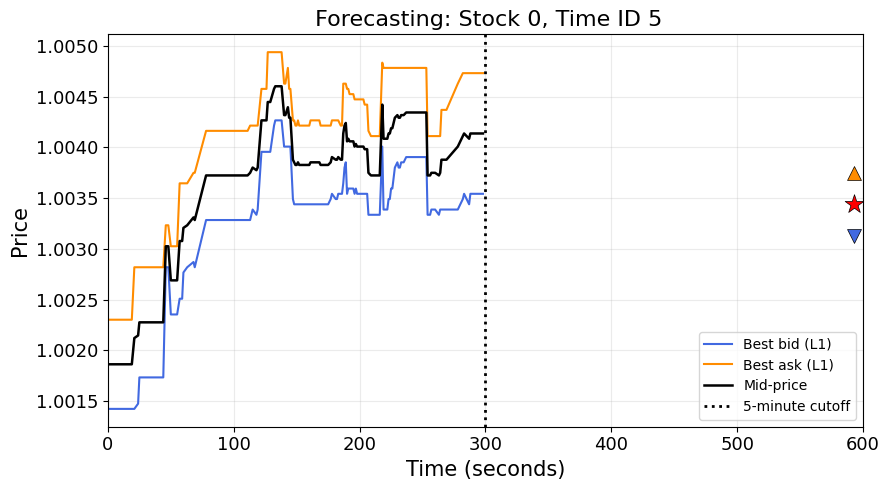

In [7]:
st_id = 0
tid = 5

# Load data
book = load_stock("book", st_id).copy()

book = book[book["time_id"] == tid].sort_values(
    "seconds_in_bucket"
).copy()

if book.empty:
    print(f"No order-book observations for stock {st_id}, time_id {tid}")

else:
    # Calculate mid-price over the full 10-minute interval
    book["MidPrice"] = (
        book["ask_price1"] + book["bid_price1"]
    ) / 2

    # Extract the actual final target
    final_price = book["MidPrice"].iloc[-1]
    final_time = book["seconds_in_bucket"].iloc[-1]

    # Only plot observed prices from the first 9 minutes
    book_9min = book[book["seconds_in_bucket"] <= 300].copy()

    fig, ax = plt.subplots(figsize=(9, 5))

    t = book_9min["seconds_in_bucket"]

    # Best bid
    ax.plot(
        t, book_9min["bid_price1"],
        color="royalblue", linewidth=1.5,
        label="Best bid (L1)"
    )

    # Best ask
    ax.plot(
        t, book_9min["ask_price1"],
        color="darkorange", linewidth=1.5,
        label="Best ask (L1)"
    )

    # Mid-price
    ax.plot(
        t, book_9min["MidPrice"],
        color="black", linewidth=1.8,
        label="Mid-price"
    )

    # Actual final mid-price (target)
    ax.scatter(
        final_time, final_price,
        color="red", marker="*", s=200,
        edgecolors="black", linewidths=0.5,
       # label=f"Target mid-price = {final_price:.5f}",
        zorder=5
    )

    # 9-minute cutoff
    ax.axvline(
        300, color="black", linestyle=":",
        linewidth=2, label="5-minute cutoff"
    )

    # Axis formatting
    ax.set_xlim(0, 600)
    ax.set_xlabel("Time (seconds)", fontsize=15)
    ax.set_ylabel("Price", fontsize=15)
    ax.tick_params(axis="both", labelsize=13)

    ax.set_title(
        f" Forecasting: Stock {st_id}, Time ID {tid}",
        fontsize=16
    )

    ax.grid(alpha=0.25)
    ax.legend(fontsize=10, loc="lower right")

    # Actual final bid and ask
    final_bid = book["bid_price1"].iloc[-1]
    final_ask = book["ask_price1"].iloc[-1]

    ax.scatter(
    final_time, final_bid,
    color="royalblue", marker="v", s=100,
    edgecolors="black", linewidths=0.5,
    label=f"Final bid = {final_bid:.5f}",
    zorder=6
    )

    ax.scatter(
    final_time, final_ask,
    color="darkorange", marker="^", s=100,
    edgecolors="black", linewidths=0.5,
    label=f"Final ask = {final_ask:.5f}",
    zorder=6
    )

    plt.tight_layout()
    plt.show()

# Visualising Mid-Price Trajectories Across Random Time Windows

Plots mid-price trajectories for randomly selected time IDs from two selected stocks (500 time IDs per stock).

The code:
- Loads and sorts order-book data for each stock.
- Calculates the mid-price from the best bid and ask.
- Randomly samples time IDs using a fixed seed for reproducibility.
- Plots mid-price trajectories over the first five minutes.
- Marks the final observed mid-price for each time window.
- Highlights the prediction period (300–600 seconds) and the 300-second prediction cutoff.

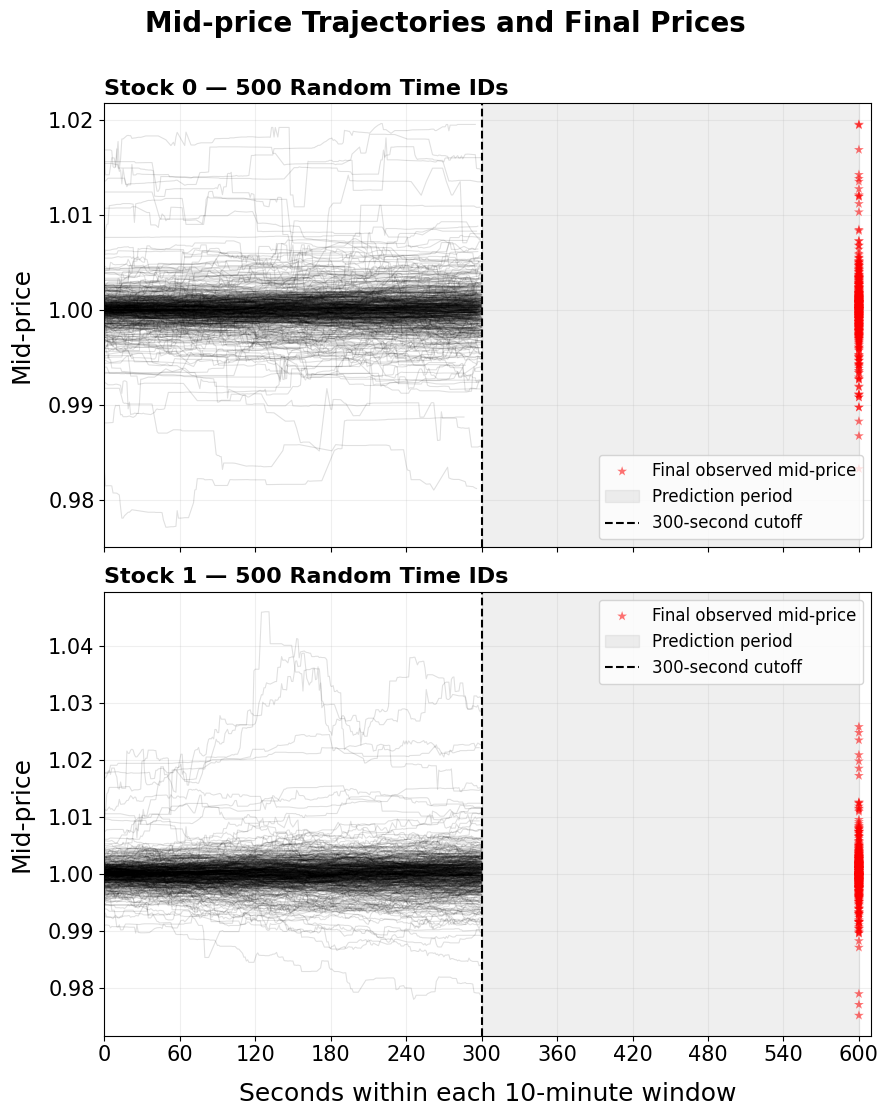

In [8]:
# Choose stocks
stock_ids = [0, 1]

# Number of time_ids to sample per stock
n_samples = 500

rng = np.random.default_rng(seed=42)

# Narrower figure
fig, axes = plt.subplots(
    len(stock_ids), 1,
    figsize=(9, 11),
    sharex=True
)

axes = np.atleast_1d(axes)

for ax, st_id in zip(axes, stock_ids):

    # Load order-book data
    book = load_stock("book", st_id).copy()
    book = book.sort_values(["time_id", "seconds_in_bucket"])

    # Calculate mid-price
    book["MidPrice"] = (book["ask_price1"] + book["bid_price1"]) / 2

    # Randomly select time_ids
    available_time_ids = book["time_id"].unique()

    sampled_time_ids = rng.choice(
        available_time_ids,
        size=min(n_samples, len(available_time_ids)),
        replace=False
    )

    sampled_book = book[book["time_id"].isin(sampled_time_ids)]

    # Store final prices
    final_prices = []

    for tid, d in sampled_book.groupby("time_id"):

        d = d.sort_values("seconds_in_bucket")

        # First 9 minutes
        first_9 = d[d["seconds_in_bucket"] <= 300]

        # Final observed mid-price before 600 seconds
        final_price = d.loc[
            d["seconds_in_bucket"] < 600,
            "MidPrice"
        ]

        if first_9.empty or final_price.empty:
            continue

        # Mid-price trajectory: black lines
        ax.plot(
            first_9["seconds_in_bucket"],
            first_9["MidPrice"],
            color="black",
            alpha=0.12,
            linewidth=0.8
        )

        final_prices.append(final_price.iloc[-1])

    # Final mid-prices: red stars
    ax.scatter(
        [600] * len(final_prices),
        final_prices,
        color="red",
        marker="*",
        s=55,
        alpha=0.55,
        edgecolors="none",
        label="Final observed mid-price",
        zorder=5
    )

    # Shade final 60-second prediction period
    ax.axvspan(
        300, 600,
        color="grey",
        alpha=0.12,
        label="Prediction period"
    )

    # Prediction cutoff
    ax.axvline(
        300,
        color="black",
        linestyle="--",
        linewidth=1.5,
        label="300-second cutoff"
    )

    ax.set_title(
        f"Stock {st_id} — {len(sampled_time_ids)} Random Time IDs",
        fontsize=16,
        fontweight="bold",
        loc="left"
    )

    ax.set_ylabel("Mid-price", fontsize=18, labelpad=10)

    ax.tick_params(axis="both", labelsize=15)

    ax.grid(alpha=0.2)

    ax.legend(loc="best", fontsize=12)

    ax.set_xlim(0, 610)
    ax.set_xticks(np.arange(0, 601, 60))

axes[-1].set_xlabel(
    "Seconds within each 10-minute window",
    fontsize=18,
    labelpad=12
)

fig.suptitle(
    "Mid-price Trajectories and Final Prices",
    fontsize=20,
    fontweight="bold",
    y=1.01
)

plt.tight_layout()
plt.show()

### Trade Feature Engineering

Generates trade-based features for each stock and time window, using only trades observed up to the 300-second cutoff.

The code:
- Loads and filters trade data up to the specified cutoff.
- Groups trades by `time_id`.
- Calculates features over the most recent 60-, 120-, and 180-second windows.
- Computes trade activity features, including trade count, total and average trade size, and total order count.
- Computes price-related features, including price range, last traded price, volume-weighted average price (VWAP), and relative price change.
- Assigns `NaN` to price-related features when a window contains no trades.

In [9]:
def engineer_trade_features(st_id, cutoff=300, windows=(60, 120, 180)):

    trades = load_stock("trade", st_id)
    df = trades.copy()

    df = df[df["seconds_in_bucket"] <= cutoff].copy()
    df = df.sort_values(["time_id", "seconds_in_bucket"])

    results = []

    for time_id, g in df.groupby("time_id", sort=False):
        row = {"stock_id": st_id,"time_id": time_id}

        for window in windows:
            recent = g[g["seconds_in_bucket"] > cutoff - window]

            prefix = f"trade_{window}s_"

            row[prefix + "count"] = len(recent)
            row[prefix + "size_sum"] = recent["size"].sum()
            row[prefix + "size_mean"] = recent["size"].mean()
            row[prefix + "order_count_sum"] = recent["order_count"].sum()

            if len(recent) > 0:
                prices = recent["price"]
                size_sum = recent["size"].sum()


                row[prefix + "price_range"] = prices.max() - prices.min()
                row[prefix + "last_price"] = prices.iloc[-1]

                row[prefix + "vwap"] = ((recent["price"] * recent["size"]).sum() / size_sum
                    if size_sum != 0 else np.nan)

                row[prefix + "price_change"] = (prices.iloc[-1] / prices.iloc[0] - 1
                     if prices.iloc[0] != 0 else np.nan )
            else:
                for feature in ["price_range", "last_price", "vwap", "price_change"]:
                    row[prefix + feature] = np.nan

        results.append(row)

    return pd.DataFrame(results)


# Order-Book Feature Engineering

Generates order-book features for each stock and time window, using only information available up to the 300-second cutoff.

The code:
- Loads and sorts order-book snapshots by `time_id` and timestamp.
- Calculates basic price features, including mid-price, bid-ask spread, and relative spread.
- Computes microprice, microprice tilt, and one-level order-book imbalance.
- Calculates two-level bid depth, ask depth, total depth, and two-level imbalance.
- Computes log returns within each time window.
- Optionally prints diagnostic information, including dataset shape, number of time IDs, and missing values.
- Extracts the last observed mid-price at 300 seconds for each stock and time ID.
- Aggregates order-book features over the most recent 60-, 120-, and 180-second windows.
- Computes mean and standard deviation of spread, imbalance, and depth features, together with mid-price momentum and realized variance.
- Merges the features into one row per stock and time ID.


In [10]:
def engineer_orderbook_features(st_id, diagnostics=False, windows=(60, 120, 180)):

    # Load order-book data for one stock
    df = load_stock("book", st_id).copy()

    # Sort snapshots within each time window
    df = df.sort_values(["time_id", "seconds_in_bucket"]).copy()

    # Basic price features
    df["MidPrice"] = (df["ask_price1"] + df["bid_price1"]) / 2

    df["BidAskSpread"] = df["ask_price1"] / df["bid_price1"] - 1

    df["RelativeSpread"] = (df["ask_price1"] - df["bid_price1"]) / df["MidPrice"]

    # Weighted average price (microprice)
    total_top_size = df["bid_size1"] + df["ask_size1"]

    df["WtAvgPrice"] = (df["bid_price1"] * df["ask_size1"] + df["ask_price1"] * df["bid_size1"]) / total_top_size.replace(0, np.nan)

    # Microprice relative to mid-price
    df["microprice_tilt"] = (df["WtAvgPrice"] - df["MidPrice"]) / df["MidPrice"].replace(0, np.nan)

    # One-level order-book imbalance
    df["imbalance"] = (df["bid_size1"] - df["ask_size1"]) / total_top_size.replace(0, np.nan)

    # Two-level depth and imbalance
    df["bid_depth"] = df["bid_size1"] + df["bid_size2"]
    df["ask_depth"] = df["ask_size1"] + df["ask_size2"]

    df["total_depth"] = df["bid_depth"] + df["ask_depth"]

    df["imbalance_2level"] = (df["bid_depth"] - df["ask_depth"]) / df["total_depth"].replace(0, np.nan)

    # Log returns within each time_id
    df["log_return"] = (np.log(df["MidPrice"].where(df["MidPrice"] > 0)).groupby(df["time_id"]).diff())


    if diagnostics:
        print(f"Stock ID: {st_id}")
        print("Book shape:", df.shape)
        print("Number of time IDs:", df["time_id"].nunique())
        print("Missing values:\n", df.isnull().sum())

    # Only use information available up to second 300
    df = df[df["seconds_in_bucket"] <= 300].copy()

    # Snapshot-level variables to aggregate
    feature_cols = [ "BidAskSpread","RelativeSpread","microprice_tilt","imbalance", "bid_depth", "ask_depth","total_depth","imbalance_2level"]

    keys = ["stock_id", "time_id"]
    df["stock_id"] = st_id

    last_midprice_300 = (df.groupby(["stock_id", "time_id"])["MidPrice"].last().rename("last_midprice_300"))

    all_window_features = []

    for window in windows:

        # For example, window=60 selects seconds 480 to 540
        recent = df[df["seconds_in_bucket"] >= 300 - window].copy()

        grouped = recent.groupby(keys, sort=False)

        # Mean features
        means = grouped[feature_cols].mean()
        means.columns = [f"{col}_mean_{window}s" for col in means.columns]

        # Standard deviation captures variability
        stds = grouped[feature_cols].std()
        stds.columns = [f"{col}_std_{window}s" for col in stds.columns]

        # Mid-price momentum over the selected window
        prices = grouped["MidPrice"].agg(["first", "last"])

        momentum = np.log(prices["last"] / prices["first"]).rename(f"momentum_{window}s")

        # Realized variance, using returns within this window only
        recent["window_log_return"] = (np.log(recent["MidPrice"].where(recent["MidPrice"] > 0)).groupby([recent["stock_id"], recent["time_id"]]).diff())

        realized_var = (recent.groupby(keys)["window_log_return"].apply(lambda x: (x.dropna() ** 2).sum()).rename(f"realized_var_{window}s"))

        # Combine the features for this window
        window_features = pd.concat([means, stds, momentum, realized_var], axis=1).reset_index()

        all_window_features.append(window_features)

    # Join 30s, 60s and 120s features into one row per stock/time_id
    result = all_window_features[0]

    for window_features in all_window_features[1:]:result = result.merge(window_features, on=keys,how="outer", validate="one_to_one")

    result = result.merge(last_midprice_300.reset_index(), on=keys, how="left", validate="one_to_one")

    return result

# Feature Extraction Across All Stocks

Applies the order-book and trade feature engineering functions to every available stock ID.

The code:
- Sorts the available stock IDs in ascending order.
- Iterates over each stock ID.
- Generates order-book features using `engineer_orderbook_features()`.
- Generates trade features using `engineer_trade_features()`.
- Stores the resulting feature DataFrames in separate lists: `all_features` and `all_trade_features`.
- Prints the stock ID currently being processed to track progress.

In [11]:
stock_ids=np.sort(book_st_id)

all_features = []
all_trade_features = []

for st_id in stock_ids:
    print(f"Processing stock {st_id}")

    features = engineer_orderbook_features(st_id=st_id, diagnostics=False)
    trade_features = engineer_trade_features(st_id=st_id)

    all_features.append(features)
    all_trade_features.append(trade_features)






Processing stock 0
Processing stock 1
Processing stock 2
Processing stock 3
Processing stock 4
Processing stock 5
Processing stock 6
Processing stock 7
Processing stock 8
Processing stock 9
Processing stock 10
Processing stock 11
Processing stock 13
Processing stock 14
Processing stock 15
Processing stock 16
Processing stock 17
Processing stock 18
Processing stock 19
Processing stock 20
Processing stock 21
Processing stock 22
Processing stock 23
Processing stock 26
Processing stock 27
Processing stock 28
Processing stock 29
Processing stock 30
Processing stock 31
Processing stock 32
Processing stock 33
Processing stock 34
Processing stock 35
Processing stock 36
Processing stock 37
Processing stock 38
Processing stock 39
Processing stock 40
Processing stock 41
Processing stock 42
Processing stock 43
Processing stock 44
Processing stock 46
Processing stock 47
Processing stock 48
Processing stock 50
Processing stock 51
Processing stock 52
Processing stock 53
Processing stock 55
Processing

# Combining Order-Book and Trade Features

Combines the order-book and trade features from all stocks into a single feature matrix and compares its coverage with the target dataset.

The code:
- Concatenates the per-stock order-book feature DataFrames into `X_orderbook`.
- Concatenates the per-stock trade feature DataFrames into `X_trade`.
- Prints the dimensions of both feature datasets.
- Merges the two datasets using `stock_id` and `time_id`, with an inner join.
- Retains only stock/time ID combinations present in both datasets, thereby excluding windows with no corresponding trade features.
- Validates that each stock/time ID combination appears only once in each dataset.
- Prints the dimensions and coverage of the merged feature matrix.
- Displays the first few rows of the feature matrix and target matrix, along with their dimensions and stock/time ID counts.


In [12]:
# Combine every stock
X_orderbook = pd.concat(all_features, ignore_index=True)
X_trade = pd.concat(all_trade_features, ignore_index=True)

print("Order-book features:", X_orderbook.shape)
print("Trade features:", X_trade.shape)

## discard the time ids when there is no trade

X = X_orderbook.merge(X_trade, on=["stock_id", "time_id"],
    how="inner", validate="one_to_one")


print("Feature matrix shape:", X.shape)
print("Number of stocks:", X["stock_id"].nunique())
print("Number of stock/time_id rows:", X[["stock_id", "time_id"]].drop_duplicates().shape[0])

display(X.head())

print("Target matrix shape:", Y.shape)
print("Number of stocks:", Y["stock_id"].nunique())
print("Number of stock/time_id rows:", Y[["stock_id", "time_id"]].drop_duplicates().shape[0])

display(Y.head())

Order-book features: (428932, 57)
Trade features: (428736, 26)
Feature matrix shape: (428736, 81)
Number of stocks: 112
Number of stock/time_id rows: 428736


,stock_id,time_id,BidAskSpread_mean_60s,RelativeSpread_mean_60s,microprice_tilt_mean_60s,imbalance_mean_60s,bid_depth_mean_60s,ask_depth_mean_60s,total_depth_mean_60s,imbalance_2level_mean_60s,...,trade_120s_vwap,trade_120s_price_change,trade_180s_count,trade_180s_size_sum,trade_180s_size_mean,trade_180s_order_count_sum,trade_180s_price_range,trade_180s_last_price,trade_180s_vwap,trade_180s_price_change
0,0,5,0.000977,0.000976,-0.000127,-0.120230,110.000000,219.217391,329.217391,-0.125599,...,1.004095,0.000412,13,824,63.384615,28,0.001034,1.004370,1.004074,0.000163
1,0,11,0.000285,0.000285,-0.000011,-0.298502,119.000000,110.409091,229.409091,-0.265033,...,1.000106,0.000502,9,274,30.444444,14,0.000652,1.000376,1.000093,0.000452
2,0,16,0.000761,0.000761,-0.000086,-0.300889,157.944444,216.888889,374.833333,-0.150041,...,0.999476,0.000383,9,835,92.777778,22,0.001292,1.000024,0.999731,-0.000431
3,0,31,0.000774,0.000774,0.000267,0.708266,208.500000,191.400000,399.900000,0.093712,...,0.998427,0.000000,2,75,37.500000,4,0.000046,0.998427,0.998384,0.000046
4,0,62,0.000404,0.000404,0.000110,0.673817,206.466667,111.533333,318.000000,0.513744,...,0.999652,-0.000195,7,355,50.714286,21,0.000373,0.999642,0.999667,0.000132


Target matrix shape: (428932, 5)
Number of stocks: 112
Number of stock/time_id rows: 428932


,stock_id,time_id,midprice_300,midprice_last,midprice_relchange
0,0,5,1.004137,1.003439,-0.000695
1,0,11,1.000276,1.000527,0.000251
2,0,16,0.999952,0.997798,-0.002154
3,0,31,0.998381,0.997941,-0.000440
4,0,62,0.999534,0.999930,0.000396


# Data Quality Checks Before Model Training

Performs basic data quality checks on the feature matrix (`X`) and target matrix (`Y`) before model training.

The code:
- Checks for duplicate rows based on `stock_id` and `time_id` in both datasets.
- Counts the total number of missing values in the feature matrix.
- Identifies and displays features containing missing values, sorted by their number of missing entries.
- Checks for missing values in the target variables: `midprice_300`, `midprice_last`, and `midprice_relchange`.


In [13]:
# checks before training

# check if there are duplicate rows

print("Duplicate feature rows:", X.duplicated(["stock_id", "time_id"]).sum())
print("Duplicate target rows:", Y.duplicated(["stock_id", "time_id"]).sum())

print("Total NaN values in X:", X.isna().sum().sum())
print("\n NaN values per feature:")
print(X.isna().sum()[X.isna().sum() > 0].sort_values(ascending=False))

# check for NAN in Y
print("\n NaN values in Y:")
print(Y[["midprice_300", "midprice_last", "midprice_relchange"]].isna().sum())


Duplicate feature rows: 0
Duplicate target rows: 0
Total NaN values in X: 86693

 NaN values per feature:
trade_60s_vwap               13741
trade_60s_price_change       13741
trade_60s_price_range        13741
trade_60s_last_price         13741
trade_60s_size_mean          13741
trade_120s_price_range        2629
trade_120s_size_mean          2629
trade_120s_last_price         2629
trade_120s_vwap               2629
trade_120s_price_change       2629
trade_180s_last_price          817
trade_180s_size_mean           817
trade_180s_price_change        817
trade_180s_vwap                817
trade_180s_price_range         817
bid_depth_std_60s               75
RelativeSpread_std_60s          75
BidAskSpread_std_60s            75
imbalance_2level_std_60s        75
total_depth_std_60s             75
ask_depth_std_60s               75
microprice_tilt_std_60s         75
imbalance_std_60s               75
RelativeSpread_mean_60s         15
BidAskSpread_mean_60s           15
imbalance_2level_me

# Investigating Missing Values in the Feature Matrix

Investigates the sources of missing values in the trade and order-book features for the 60-, 120-, and 180-second windows.

The code:

- **Trade features:**
  - Counts windows with zero trades.
  - Checks missing values in trade-related features, including price range, average trade size, last traded price, VWAP, and price change.
  - Examines whether missing values are associated with windows containing no trades.

- **Order-book features:**
  - Loads order-book data for each stock represented in the feature matrix.
  - Counts the number of order-book observations in each time window (60, 120, and 180 seconds).
  - Includes stock/time ID combinations with zero observations.
  - Counts windows containing zero or only one order-book observation.



In [14]:
# check the reason of NaN values in X: zero trade windows, zero orderbook windows, one orderbook windows

for window in [60, 120, 180]:

    count_col = f"trade_{window}s_count"

    zero_trades = (X[count_col] == 0).sum()
    one_trade = (X[count_col] == 1).sum()

    print(f"\n--- {window}-second window ---")
    print("Zero-trade windows:", zero_trades)
  #  print("One-trade windows:", one_trade)

    for feature in [
        "price_range",
        "size_mean",
        "last_price",
        "vwap",
        "price_change",
        "price_std"
    ]:
        col = f"trade_{window}s_{feature}"

        if col in X.columns:
            nan_count = X[col].isna().sum()
            print(f"{feature} NaNs: {nan_count}")

windows = [60, 120, 180]
all_counts = []

# Count observations in each window for every stock/time_id
for st_id in sorted(X["stock_id"].unique()):

    df_stock = load_stock("book", st_id).copy()

    stock_time_ids = X.loc[X["stock_id"] == st_id, "time_id"].unique()

    for window in windows:

        start_time = 300 - window

        df_recent = df_stock[
            (df_stock["seconds_in_bucket"] >= start_time) &
            (df_stock["seconds_in_bucket"] <= 300)]

        counts = df_recent.groupby("time_id").size()
        counts = counts.reindex(stock_time_ids, fill_value=0)

        temp = counts.rename("n_observations").reset_index()
        temp = temp.rename(columns={"index": "time_id"})
        temp["stock_id"] = st_id
        temp["window"] = window

        all_counts.append(temp)

counts_all_windows = pd.concat(all_counts, ignore_index=True)


# Summarize observation counts
for window in windows:

    counts = counts_all_windows.loc[
        counts_all_windows["window"] == window,
        "n_observations"]

    print(f"\n--- {window}-second window ---")
    print("Zero-orderbook windows:", (counts == 0).sum())
    print("One-orderbook windows:", (counts == 1).sum())



--- 60-second window ---
Zero-trade windows: 13741
price_range NaNs: 13741
size_mean NaNs: 13741
last_price NaNs: 13741
vwap NaNs: 13741
price_change NaNs: 13741

--- 120-second window ---
Zero-trade windows: 2629
price_range NaNs: 2629
size_mean NaNs: 2629
last_price NaNs: 2629
vwap NaNs: 2629
price_change NaNs: 2629

--- 180-second window ---
Zero-trade windows: 817
price_range NaNs: 817
size_mean NaNs: 817
last_price NaNs: 817
vwap NaNs: 817
price_change NaNs: 817

--- 60-second window ---
Zero-orderbook windows: 15
One-orderbook windows: 60

--- 120-second window ---
Zero-orderbook windows: 0
One-orderbook windows: 1

--- 180-second window ---
Zero-orderbook windows: 0
One-orderbook windows: 0


# Handling Missing Values in the Feature Matrix

Creates a copy of the original feature matrix (`X1`) and begins treating missing values in trade and order-book features.

The code:
- Copies `X` into `X1`, preserving the original feature matrix.
- For the 60-, 120-, and 180-second windows:
  - Replaces missing last traded prices and VWAP values with the last observed mid-price at 300 seconds.
  - Replaces missing price changes and price ranges with zero.
  - Replaces missing average trade sizes with zero.
- Defines a list of order-book mean features for subsequent median imputation.



In [15]:
# treating the NaN values in X

X1 = X.copy()

X1["trade_60s_last_price"] = (X1["trade_60s_last_price"].fillna(X1["last_midprice_300"]))
X1["trade_60s_vwap"] = (X1["trade_60s_vwap"].fillna(X1["last_midprice_300"]))
X1["trade_60s_price_change"] = X1["trade_60s_price_change"].fillna(0)
X1["trade_60s_price_range"] = X1["trade_60s_price_range"].fillna(0)
X1["trade_60s_size_mean"] = X1["trade_60s_size_mean"].fillna(0)

X1["trade_120s_last_price"] = (X1["trade_120s_last_price"].fillna(X1["last_midprice_300"]))
X1["trade_120s_vwap"] = (X1["trade_120s_vwap"].fillna(X1["last_midprice_300"]))
X1["trade_120s_price_change"] = X1["trade_120s_price_change"].fillna(0)
X1["trade_120s_price_range"] = X1["trade_120s_price_range"].fillna(0)
X1["trade_120s_size_mean"] = X1["trade_120s_size_mean"].fillna(0)

X1["trade_180s_last_price"] = (X1["trade_180s_last_price"].fillna(X1["last_midprice_300"]))
X1["trade_180s_vwap"] = (X1["trade_180s_vwap"].fillna(X1["last_midprice_300"]))
X1["trade_180s_price_change"] = X1["trade_180s_price_change"].fillna(0)
X1["trade_180s_price_range"] = X1["trade_180s_price_range"].fillna(0)
X1["trade_180s_size_mean"] = X1["trade_180s_size_mean"].fillna(0)

# Mean features: median imputation

mean_cols = [
    "RelativeSpread_mean_60s",
    "BidAskSpread_mean_60s",
    "imbalance_2level_mean_60s",
    "total_depth_mean_60s",
    "ask_depth_mean_60s",
    "bid_depth_mean_60s",
    "microprice_tilt_mean_60s",
    "imbalance_mean_60s"
]


for col in mean_cols:
    X1[col] = X1[col].fillna(X1[col].median())

mean_cols = [c for c in X1.columns if "_mean_" in c]


std_cols = [
    "bid_depth_std_60s",
    "RelativeSpread_std_60s",
    "BidAskSpread_std_60s",
    "imbalance_2level_std_60s",
    "total_depth_std_60s",
    "ask_depth_std_60s",
    "microprice_tilt_std_60s",
    "imbalance_std_60s"
]

X1[std_cols] = X1[std_cols].fillna(0)

X1["momentum_60s"] = X1["momentum_60s"].fillna(0)
X1["realized_var_60s"] = X1["realized_var_60s"].fillna(0)


std_cols_120 = [
    "total_depth_std_120s",
    "ask_depth_std_120s",
    "bid_depth_std_120s",
    "imbalance_std_120s",
    "microprice_tilt_std_120s",
    "RelativeSpread_std_120s",
    "BidAskSpread_std_120s",
    "imbalance_2level_std_120s"
]

X1[std_cols_120] = X1[std_cols_120].fillna(0)

print("Total NaN values in X:", X1.isna().sum().sum())
print("\n NaN values per feature:")
print(X1.isna().sum()[X1.isna().sum() > 0].sort_values(ascending=False))



Total NaN values in X: 0

 NaN values per feature:
Series([], dtype: int64)


# Investigating Missing Target Values

Investigates whether missing target values are caused by the absence of order-book observations after the 300-second cutoff.

The code:
- Loads and sorts order-book data for each stock.
- Groups observations by `time_id`.
- Checks whether each stock/time ID group contains at least one observation after 300 seconds.
- Combines the availability information across all stocks.
- Counts the total number of stock/time ID groups without observations after 300 seconds.
- Calculates the percentage of groups without such observations.
- Provides a stock-wise breakdown of total groups and groups with observations after 300 seconds.

**Purpose:** Determines whether missing final mid-price targets are associated with the absence of order-book observations during the prediction period (300–600 seconds).

In [16]:
# checking the reason of NaN values in Y: no observation after 540 seconds

availability_all = []

for st_id in sorted(X["stock_id"].unique()):

    # Load order-book data
    df = load_stock("book", st_id).copy()

    # Sort by time
    df = df.sort_values(["time_id", "seconds_in_bucket"])

    # Check whether each time_id has observations after 540 seconds
    availability = (
        df.groupby("time_id")["seconds_in_bucket"]
          .apply(lambda x: (x > 300).any())
          .reset_index(name="has_observations_after_300")
    )

    availability["stock_id"] = st_id

    availability_all.append(availability)

# Combine all stocks
availability_all = pd.concat(availability_all, ignore_index=True)

# Count missing final-minute observations
total_groups = len(availability_all)

no_final_observations = (
    ~availability_all["has_observations_after_300"]
).sum()

# Results
print("Total stock-time_id groups:", total_groups)

print("Groups with no observations after 300 seconds:",
      no_final_observations)

print("Percentage without final-minute observations:",
      round(100 * no_final_observations / total_groups, 2), "%")

# Breakdown by stock
print("\nBreakdown by stock:")

print(
    availability_all.groupby("stock_id")[
        "has_observations_after_300"
    ].agg(
        total_groups="count",
        groups_with_observations="sum"
    )
)

Total stock-time_id groups: 428932
Groups with no observations after 300 seconds: 0
Percentage without final-minute observations: 0.0 %

Breakdown by stock:
          total_groups  groups_with_observations
stock_id                                        
0                 3830                      3830
1                 3830                      3830
2                 3830                      3830
3                 3830                      3830
4                 3830                      3830
...                ...                       ...
122               3830                      3830
123               3830                      3830
124               3830                      3830
125               3830                      3830
126               3830                      3830

[112 rows x 2 columns]


# Removing Rows with Invalid Targets

Removes observations with missing target values and ensures that the feature and target matrices contain matching stock/time ID combinations.

The code:
- Copies the processed feature matrix (`X1`) into `X_updated`.
- Removes rows from the target matrix (`Y`) where any of the three target variables (`midprice_300`, `midprice_last`, or `midprice_relchange`) is missing.
- Prints the total number of remaining missing values in both datasets.
- Uses an inner join on `stock_id` and `time_id` to retain only feature rows with valid corresponding targets.
- Reconstructs `Y_updated` using the same stock/time ID combinations as `X_updated`.
- Compares the unique stock/time ID combinations in both datasets to check that they match.


In [17]:
# Remove rows with invalid targets

# rows which does not contain trade activity has been dropped from X
X_updated = X1.copy()

# drop rows where there is NAN
Y_updated = Y.dropna(subset=["midprice_300", "midprice_last", "midprice_relchange"]).copy()

print("Total NaN values in X:", X_updated.isna().sum().sum())
print("Total NaN values in Y:", Y_updated.isna().sum().sum())


# Keep only feature rows whose targets are valid
keys = ["stock_id", "time_id"]

X_updated = X_updated.merge(Y_updated[keys], on=keys, how="inner", validate="one_to_one")
Y_updated = X_updated[keys].merge(Y_updated, on=keys, how="inner", validate="one_to_one")


print("Rows in Y_updated:", len(Y_updated))
print("Rows in X_updated:", len(X_updated))


# checks if all stock id and time id has corresponding rows in X and Y
X_keys = X_updated[["stock_id", "time_id"]].drop_duplicates()
Y_keys = Y_updated[["stock_id", "time_id"]].drop_duplicates()

comparison = X_keys.merge(Y_keys, on=["stock_id", "time_id"], how="outer", indicator=True)

print(comparison["_merge"].value_counts())


Total NaN values in X: 0
Total NaN values in Y: 0
Rows in Y_updated: 428736
Rows in X_updated: 428736
_merge
both          428736
left_only          0
right_only         0
Name: count, dtype: int64


# Visualising the Distribution of Final Mid-Prices

Examines the distribution of the final observed mid-price (`midprice_last`) across all valid stock/time ID observations.

The code:
- Extracts the final mid-price from `Y_updated`.
- Calculates its mean and median.
- Plots a histogram with 100 bins to visualise the distribution.
- Marks the mean and median with vertical reference lines.
- Adjusts the axis labels, limits, grid, and legend for readability.
- Prints descriptive statistics, including count, mean, standard deviation, minimum, quartiles, and maximum.


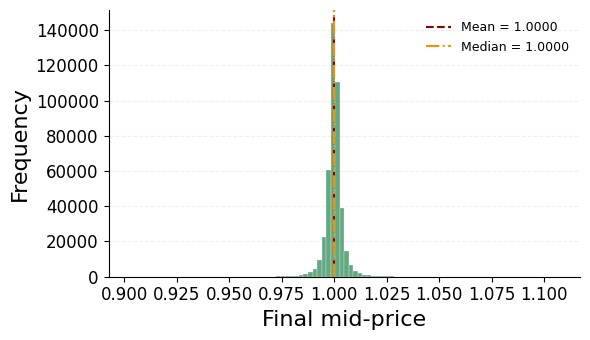

count    428736.000000
mean          1.000016
std           0.004425
min           0.896758
25%           0.998378
50%           1.000000
75%           1.001659
max           1.112807
Name: midprice_last, dtype: float64


In [18]:
price = Y_updated["midprice_last"]

mean_price = price.mean()
median_price = price.median()
fig, ax = plt.subplots(figsize=(6, 3.5))

sns.histplot(
    price,
    bins=100,
    color="seagreen",
    alpha=0.75,
    edgecolor="white",
    linewidth=0.2,
    ax=ax
)

ax.axvline(
    mean_price,
    color="darkred",
    linestyle="--",
    linewidth=1.5,
    label=f"Mean = {mean_price:.4f}"
)

ax.axvline(
    median_price,
    color="darkorange",
    linestyle="-.",
    linewidth=1.5,
    label=f"Median = {median_price:.4f}"
)

#ax.set_title("Distribution of relative change in mid price", fontsize=13, pad=8)
ax.set_xlabel("Final mid-price", fontsize=16)
ax.set_ylabel("Frequency", fontsize=16)

ax.tick_params(axis="both", labelsize=12)
ax.grid(axis="y", linestyle="--", alpha=0.2)
ax.set_axisbelow(True)

ax.legend(fontsize=9, frameon=False)

sns.despine()
x_min = price.min()
x_max = price.max()
margin = 0.02 * (x_max - x_min)

ax.set_xlim(x_min - margin, x_max + margin)
plt.tight_layout()
plt.show()



print(price.describe().round(6))

# Feature Selection: Removing Selected Features

After recursively performing exploratory data analysis, analyzing correlations with the target, calculating feature correlation matrix, variance inflation factors, and evaluating model results a set of features are removed from the processed feature matrix (`X_updated`).

The code:
- Defines a list of features to exclude from the model input.
- Removes selected order-book features
- Removes selected trade features
- Drops the specified columns from `X_updated`.
- Prints the shape of the resulting feature matrix.

In [19]:
drop_features = [
    "BidAskSpread_mean_60s",
    "BidAskSpread_mean_120s",
    "BidAskSpread_mean_180s",

    "BidAskSpread_std_60s",
    "BidAskSpread_std_120s",
    "BidAskSpread_std_180s",

    "trade_120s_last_price",
    "trade_180s_last_price",

    "total_depth_mean_180s",
    "total_depth_mean_120s",
     "total_depth_mean_60s",

    "total_depth_std_180s",
    "total_depth_std_120s",

    "bid_depth_mean_180s",
    "bid_depth_mean_120s",

    "bid_depth_std_120s",
    "bid_depth_std_60s",

    "ask_depth_mean_180s",
    "ask_depth_mean_120s",

    "ask_depth_std_180s",
    "bid_depth_std_180s",

    "ask_depth_std_120s",

    "trade_120s_vwap",
    "trade_180s_vwap",

    "RelativeSpread_mean_180s",
    "RelativeSpread_mean_120s",
    "RelativeSpread_mean_60s",


    "RelativeSpread_std_180s",
    "RelativeSpread_std_120s",

    "microprice_tilt_std_180s",
    "microprice_tilt_std_120s",
    "microprice_tilt_std_60s",

    "microprice_tilt_mean_180s",
    "microprice_tilt_mean_120s",

    "trade_180s_count",
    "trade_120s_count",

    "trade_180s_order_count_sum",
    "trade_120s_order_count_sum",

    "trade_180s_size_sum",
    "trade_120s_size_sum",

    "trade_180s_size_mean",

    "trade_60s_last_price",

    "trade_180s_price_range",
    "trade_120s_price_range",

    "trade_180s_price_change",
    "trade_120s_price_change",

     "trade_60s_price_change",

    "realized_var_180s",

    "imbalance_2level_mean_120s",
    "imbalance_2level_std_120s",
    "imbalance_2level_mean_180s",
    "imbalance_2level_std_180s",

    "imbalance_mean_180s",
    "imbalance_mean_120s",

    "imbalance_std_120s",
     "realized_var_120s",
     "imbalance_std_180s",

     "momentum_180s",
     "momentum_120s"

]


X_updated = X_updated.drop(columns=drop_features)

print("Shape:", X_updated.shape)

Shape: (428736, 22)


# Correlation Analysis and Feature Relationships

Examines the relationship between individual features and the final mid-price (`midprice_last`), as well as correlations among the features themselves.

The code:
- Creates the feature matrix by excluding identifiers (`stock_id`, `time_id`) and `last_midprice_300`.
- Selects `midprice_last` as the target variable.
- Calculates Pearson and Spearman correlations between each feature and the target.
- Combines the correlation coefficients into a summary table and ranks features by the absolute value of their Pearson correlation.
- Displays the 15 features with the strongest absolute Pearson correlations.
- Plots the Pearson and Spearman correlations of these top 15 features for comparison.
- Calculates the pairwise Pearson correlation matrix between all features.
- Visualises the feature correlation matrix using a heatmap.


                            Pearson  Spearman  abs_Pearson
trade_60s_vwap             0.817395  0.752048     0.817395
momentum_60s               0.257765  0.235624     0.257765
imbalance_2level_mean_60s  0.072826  0.098899     0.072826
imbalance_mean_60s         0.068312  0.094086     0.068312
microprice_tilt_mean_60s   0.062469  0.085336     0.062469
realized_var_60s          -0.021468 -0.023148     0.021468
trade_60s_price_range     -0.017134 -0.020114     0.017134
RelativeSpread_std_60s    -0.015795 -0.007016     0.015795
ask_depth_std_60s          0.015446  0.011053     0.015446
trade_60s_order_count_sum -0.010195 -0.011879     0.010195
imbalance_2level_std_60s  -0.005156 -0.005942     0.005156
ask_depth_mean_60s        -0.004794 -0.017290     0.004794
trade_60s_count           -0.004116 -0.012049     0.004116
imbalance_std_60s         -0.003573 -0.003854     0.003573
trade_60s_size_sum         0.001200 -0.005050     0.001200


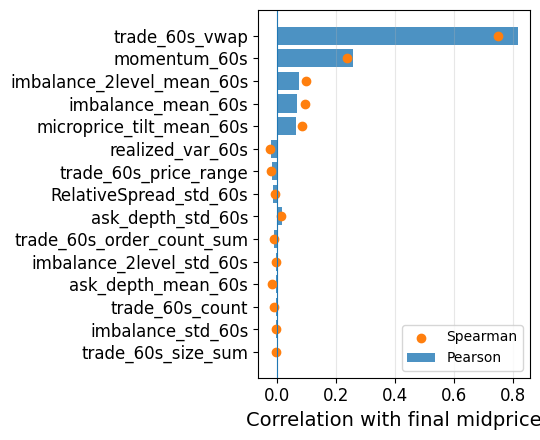

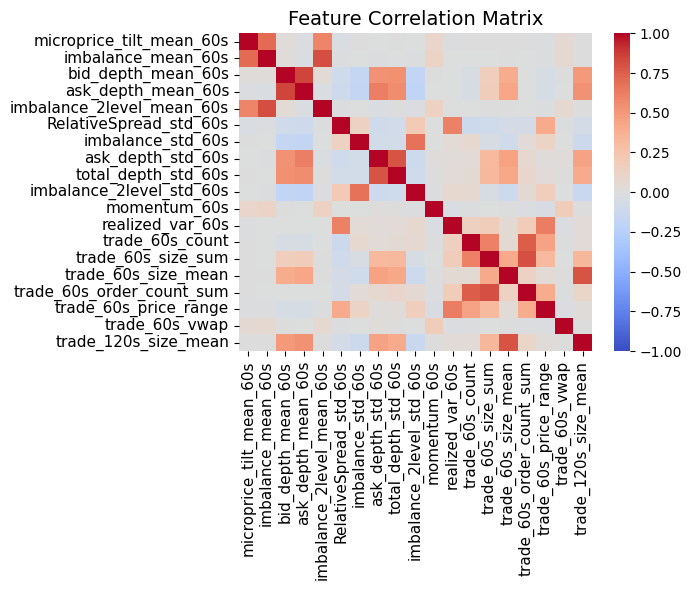

In [20]:
X_features = X_updated.drop(columns=["stock_id", "time_id", "last_midprice_300"])

# Select the target
y = Y_updated["midprice_last"]

pearson = X_features.corrwith(y, method="pearson")
spearman = X_features.corrwith(y, method="spearman")


corr_summary = pd.DataFrame({
    "Pearson": pearson,
    "Spearman": spearman
})

corr_summary["abs_Pearson"] = corr_summary["Pearson"].abs()

corr_summary = corr_summary.sort_values(
    "abs_Pearson", ascending=False
)

print(corr_summary.head(15))

top15 = corr_summary.head(15).sort_values("abs_Pearson")
fig, ax = plt.subplots(figsize=(5.5, 4.5))

y_pos = range(len(top15))

ax.barh(
    y_pos,
    top15["Pearson"],
    label="Pearson",
    alpha=0.8
)

ax.scatter(
    top15["Spearman"],
    y_pos,
    label="Spearman",
    marker="o"
)

ax.set_yticks(y_pos)
ax.set_yticklabels(top15.index)
ax.set_xlabel("Correlation with final midprice", fontsize=14)
#ax.set_title("Correlation with final midprice", fontsize=14)
ax.axvline(0, linewidth=0.8)
ax.legend()
ax.grid(axis="x", alpha=0.3)
ax.tick_params(axis="x", labelsize=12)
ax.tick_params(axis="y", labelsize=12)
plt.tight_layout()
plt.show()

# Feature-to-feature correlation
corr_matrix = X_features.corr(method="pearson")

plt.figure(figsize=(7, 6))
sns.heatmap(
    corr_matrix,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)
plt.title("Feature Correlation Matrix", fontsize=14)
plt.xticks(fontsize=11, rotation=90)
plt.yticks(fontsize=11, rotation=0)
plt.tight_layout()
plt.show()

upper = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)



# Identifying Highly Correlated Feature Pairs

Identifies pairs of input features with strong pairwise Pearson correlations to detect potential redundancy.

The code:
- Extracts the feature pairs and their correlation coefficients from the upper triangular portion of the correlation matrix.
- Converts the results into a DataFrame containing the two feature names and their correlation.
- Calculates the absolute correlation for each pair.
- Retains pairs with an absolute correlation greater than 0.80.
- Sorts the pairs in descending order of absolute correlation.
- Displays the resulting table without row indices.

In [21]:
# Find pairs with absolute correlation above 0.90
high_corr_pairs = (
    upper.stack()
    .reset_index()
)

high_corr_pairs.columns = ["Feature_1", "Feature_2", "Correlation"]

high_corr_pairs["abs_corr"] = high_corr_pairs["Correlation"].abs()

high_corr_pairs = high_corr_pairs[
    high_corr_pairs["abs_corr"] > 0.80
].sort_values("abs_corr", ascending=False)

display(high_corr_pairs.style.hide(axis="index"))




Feature_1,Feature_2,Correlation,abs_corr
bid_depth_mean_60s,ask_depth_mean_60s,0.850568,0.850568
imbalance_mean_60s,imbalance_2level_mean_60s,0.813573,0.813573
trade_60s_size_sum,trade_60s_order_count_sum,0.807701,0.807701


# Variance Inflation Factor (VIF) Analysis

Calculates the Variance Inflation Factor (VIF) for each input feature to assess multicollinearity among the predictors.

The code:
- Converts the feature matrix (`X_features`) into a NumPy array.
- Calculates the VIF for each feature using `variance_inflation_factor()` from `statsmodels`.
- Creates a summary DataFrame containing feature names and their corresponding VIF values.
- Sorts the features by VIF in descending order.
- Displays the 25 features with the highest VIF values.


In [22]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

X_vif_array = X_features.to_numpy()

vif = pd.DataFrame({
    "Feature": X_features.columns,
    "VIF": [
        variance_inflation_factor(X_vif_array, i)
        for i in range(X_vif_array.shape[1])
    ]
})

vif = vif.sort_values("VIF", ascending=False)

print(vif.head(25))

                      Feature       VIF
15  trade_60s_order_count_sum  4.878722
3          ask_depth_mean_60s  4.473454
13         trade_60s_size_sum  4.417446
1          imbalance_mean_60s  3.858454
2          bid_depth_mean_60s  3.849884
7           ask_depth_std_60s  3.309234
14        trade_60s_size_mean  3.142929
18       trade_120s_size_mean  3.083866
4   imbalance_2level_mean_60s  3.007477
8         total_depth_std_60s  2.973274
12            trade_60s_count  2.781601
11           realized_var_60s  2.276840
16      trade_60s_price_range  2.210731
0    microprice_tilt_mean_60s  2.015347
9    imbalance_2level_std_60s  1.953277
5      RelativeSpread_std_60s  1.934774
6           imbalance_std_60s  1.869309
10               momentum_60s  1.052384
17             trade_60s_vwap  1.036764


# Train-Test Split and Model Preparation

The dataset is divided into training and testing sets using an 80/20 split based on unique `time_id` values.

- Extracts the unique `time_id` values from the target dataset.
- Randomly splits these time IDs into training (80%) and testing (20%) sets using `random_state=42`.
- Selects the corresponding feature and target observations for each set, ensuring that all stocks belonging to the same `time_id` are assigned to the same split.
- Merges the features and target (`midprice_last`) using `stock_id` and `time_id` as keys, enforcing one-to-one matching.
- Separates the target variable from the input features.
- Removes identifier columns (`stock_id`, `time_id`) and `last_midprice_300` from the model input features.
- Checks the dimensions of the training and testing datasets, missing target values, and overlap between training and testing time IDs.
- Compares the target distributions in the two sets using their means, standard deviations, minimum, and maximum values.

In [23]:
from sklearn.model_selection import train_test_split

unique_time_ids = Y_updated["time_id"].unique()

# Split time IDs: 80% train, 20% test
train_time_ids, test_time_ids = train_test_split(
    unique_time_ids,
    test_size=0.20,
    random_state=42
)

print("Number of training time IDs:", len(train_time_ids))
print("Number of testing time IDs:", len(test_time_ids))

X_train = X_updated[X_updated["time_id"].isin(train_time_ids)].copy()

X_test = X_updated[X_updated["time_id"].isin(test_time_ids)].copy()

# Filter targets
Y_train = Y_updated[Y_updated["time_id"].isin(train_time_ids)].copy()

Y_test = Y_updated[Y_updated["time_id"].isin(test_time_ids)].copy()

keys = ["stock_id", "time_id"]

train_data = X_train.merge(Y_train[keys + ["midprice_last"]],on=keys, how="inner", validate="one_to_one")

test_data = X_test.merge(Y_test[keys + ["midprice_last"]], on=keys, how="inner", validate="one_to_one")

y_train = train_data["midprice_last"]

y_test = test_data["midprice_last"]

X_train_model = train_data.drop(
    columns=keys + ["midprice_last", "last_midprice_300"]
)

X_test_model = test_data.drop(
    columns=keys + ["midprice_last", "last_midprice_300"]
)

print("\nTraining features:", X_train_model.shape)
print("Training target:", y_train.shape)
print("Testing features:", X_test_model.shape)
print("Testing target:", y_test.shape)

print("\nMissing training targets:", y_train.isna().sum())
print("Missing testing targets:", y_test.isna().sum())

print("Overlapping time IDs:", len(set(train_time_ids) & set(test_time_ids)))

print("Training target mean:", y_train.mean())
print("Training target std:", y_train.std())

print("Test target mean:", y_test.mean())
print("Test target std:", y_test.std())

print("Test target min:", y_test.min())
print("Test target max:", y_test.max())


Number of training time IDs: 3064
Number of testing time IDs: 766

Training features: (342993, 19)
Training target: (342993,)
Testing features: (85743, 19)
Testing target: (85743,)

Missing training targets: 0
Missing testing targets: 0
Overlapping time IDs: 0
Training target mean: 1.0000083
Training target std: 0.004505168180912733
Test target mean: 1.0000472
Test target std: 0.004087154753506184
Test target min: 0.9437393546104431
Test target max: 1.07715904712677


# Model Training and 10-Fold Group Cross-Validation

Four regression models are evaluated using 10-fold group cross-validation, with a persistence baseline included for comparison.

- Defines four models:
  - **Mean Baseline:** predicts the mean training target.
  - **Ridge Regression:** uses median imputation, feature standardisation, and L2 regularisation (`alpha=1.0`).
  - **Elastic Net:** combines L1 and L2 regularisation, with median imputation and feature standardisation.
  - **XGBoost:** uses gradient-boosted decision trees with specified hyperparameters, including 500 estimators, maximum depth of 4, and learning rate of 0.03.
- Groups observations by `time_id` and applies `GroupKFold` with 10 folds, ensuring that observations from the same time window are kept together within each fold.
- Evaluates each model using RMSE, MAE, and R². Median imputation and standardisation are included in the pipelines where appropriate.
- Evaluates a **Persistence Baseline**, which predicts the final mid-price using the mid-price observed at 300 seconds (`last_midprice_300`), without fitting a model.
- Records the performance metrics for every fold and model.
- Displays fold-wise RMSE, MAE, and R² comparisons.
- Calculates the mean and standard deviation of each metric across the 10 folds.
- Identifies the best-performing model according to mean RMSE, MAE, and R², and reports the total computation time.


In [29]:

from sklearn.model_selection import GroupKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from xgboost import XGBRegressor
from sklearn.linear_model import ElasticNet
import time
from sklearn.metrics import (
    r2_score,
    root_mean_squared_error,
    mean_absolute_error
)

# 1. Define the three models
models = {
    "Mean Baseline": DummyRegressor(strategy="mean"),

    "Ridge Regression_alpha1": make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        Ridge(alpha=1.0)
    ),

    "Elastic Net": make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        ElasticNet(
            alpha=0.001,
            l1_ratio=0.2,
            max_iter=10000
        )
    ),



    "XGBoost": make_pipeline(
        SimpleImputer(strategy="median"),
        XGBRegressor(
            n_estimators=500,
    max_depth=4,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    tree_method="hist",
    objective="reg:squarederror",
    random_state=42,
    n_jobs=2
        )
    ),
}

# 2. Group observations by time_id
groups = train_data["time_id"].to_numpy()

# 3. Set up 10-fold cross-validation
cv = GroupKFold(n_splits=10)

# 4. Evaluate each model
all_results = []
total_start = time.time()

for model_number, (name, model) in enumerate(models.items(), start=1):

    print(f"\n{'='*55}", flush=True)
    print(f"Model {model_number}/{len(models)}: {name}", flush=True)
    print(f"Starting 10-fold cross-validation...", flush=True)
    print(f"{'='*55}", flush=True)

    model_start = time.time()

    scores = cross_validate(
        estimator=model,
        X=X_train_model,
        y=y_train,
        groups=groups,
        cv=cv,
        scoring={
            "rmse": "neg_root_mean_squared_error",
            "mae": "neg_mean_absolute_error",
             "r2": "r2"
        },
        n_jobs=-1,
        return_train_score=False,
        verbose=2
    )

    # Convert negative scores to positive errors
    fold_rmse = -scores["test_rmse"]
    fold_mae = -scores["test_mae"]
    fold_r2 = scores["test_r2"]

    for fold in range(len(fold_rmse)):
        all_results.append({
            "Model": name,
            "Fold": fold + 1,
            "RMSE": fold_rmse[fold],
            "MAE": fold_mae[fold],
            "R2": fold_r2[fold]
        })

    print(f"\n{name} completed.", flush=True)
    print(
        f"Elapsed time: {(time.time() - model_start)/60:.2f} minutes",
        flush=True
    )

    print("Fold RMSE:", np.round(fold_rmse, 6), flush=True)
    print("Fold MAE: ", np.round(fold_mae, 6), flush=True)
    print("Fold R²:  ", np.round(fold_r2, 4), flush=True)


print("\nEvaluating Persistence Baseline...", flush=True)
persistence_start = time.time()

persistence_pred = train_data["last_midprice_300"].to_numpy()

persistence_rmse = []
persistence_mae = []
persistence_r2 = []

for fold, (train_idx, val_idx) in enumerate(
    cv.split(X_train_model, y_train, groups),
    start=1
):

    actual = y_train.iloc[val_idx].to_numpy()

    predicted = persistence_pred[val_idx]

    rmse = root_mean_squared_error(actual, predicted)
    mae = mean_absolute_error(actual, predicted)
    r2 = r2_score(actual, predicted)

    persistence_rmse.append(rmse)
    persistence_mae.append(mae)
    persistence_r2.append(r2)

    all_results.append({
        "Model": "Persistence Baseline",
        "Fold": fold,
        "RMSE": rmse,
        "MAE": mae,
        "R2": r2
    })

    print(
        f"Fold {fold}: RMSE={rmse:.6f}, "
        f"MAE={mae:.6f}, R²={r2:.4f}",
        flush=True
    )

print("\nPersistence Baseline completed.", flush=True)
print(
    f"Elapsed time: {(time.time() - persistence_start)/60:.2f} minutes",
    flush=True
)

print("Fold RMSE:", np.round(persistence_rmse, 6), flush=True)
print("Fold MAE: ", np.round(persistence_mae, 6), flush=True)
print("Fold R²:  ", np.round(persistence_r2, 4), flush=True)

# 5. Store all fold results
fold_results = pd.DataFrame(all_results)

print("\nRMSE for each fold:")
print(
    fold_results.pivot(
        index="Fold",
        columns="Model",
        values="RMSE"
    ).round(6)
)

print("\nMAE for each fold:")
print(
    fold_results.pivot(
        index="Fold",
        columns="Model",
        values="MAE"
    ).round(6)
)

print("\nR² for each fold:")
print(
    fold_results.pivot(
        index="Fold",
        columns="Model",
        values="R2"
    ).round(4)
)

# 6. Summarize performance and variability
summary = (
    fold_results.groupby("Model")
    .agg(
        Mean_RMSE=("RMSE", "mean"),
        Std_RMSE=("RMSE", "std"),
        Mean_MAE=("MAE", "mean"),
        Std_MAE=("MAE", "std"),
        Mean_R2=("R2", "mean"),
        Std_R2=("R2", "std")
    )
    .sort_values("Mean_RMSE")
)

print("\n10-fold cross-validation summary:")
print(summary.round(6))

print("\nBest model by mean RMSE:", summary.index[0])
print("Best model by mean MAE:", summary["Mean_MAE"].idxmin())
print("Best model by mean R²:", summary["Mean_R2"].idxmax())

print(
    f"\nTotal elapsed time: {(time.time() - total_start)/60:.2f} minutes"
)





Model 1/4: Mean Baseline
Starting 10-fold cross-validation...


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 2 concurrent workers.



Mean Baseline completed.
Elapsed time: 0.06 minutes
Fold RMSE: [0.005399 0.004457 0.004125 0.004769 0.004185 0.004283 0.004216 0.004513
 0.004525 0.004447]
Fold MAE:  [0.002918 0.002689 0.002583 0.002909 0.002597 0.002674 0.00261  0.002729
 0.002646 0.002643]
Fold R²:   [-0.0001 -0.0006 -0.0007 -0.0004 -0.0002 -0.0005 -0.     -0.0011 -0.0026
 -0.    ]

Model 2/4: Ridge Regression_alpha1
Starting 10-fold cross-validation...


[Parallel(n_jobs=-1)]: Done  10 out of  10 | elapsed:    3.6s finished
[Parallel(n_jobs=-1)]: Using backend LokyBackend with 2 concurrent workers.



Ridge Regression_alpha1 completed.
Elapsed time: 0.21 minutes
Fold RMSE: [0.002977 0.002534 0.002333 0.0026   0.002371 0.002401 0.002407 0.002624
 0.002458 0.002448]
Fold MAE:  [0.001693 0.001586 0.001508 0.001654 0.001518 0.00155  0.001519 0.001605
 0.001528 0.001522]
Fold R²:   [0.696  0.6766 0.6799 0.7027 0.6792 0.6856 0.6741 0.6616 0.7041 0.697 ]

Model 3/4: Elastic Net
Starting 10-fold cross-validation...


[Parallel(n_jobs=-1)]: Done  10 out of  10 | elapsed:   12.2s finished
[Parallel(n_jobs=-1)]: Using backend LokyBackend with 2 concurrent workers.



Elastic Net completed.
Elapsed time: 0.23 minutes
Fold RMSE: [0.003017 0.002546 0.002344 0.002609 0.00239  0.002408 0.002402 0.002638
 0.002462 0.002466]
Fold MAE:  [0.001707 0.001589 0.001516 0.001663 0.001528 0.001555 0.001521 0.00161
 0.001531 0.001528]
Fold R²:   [0.6877 0.6734 0.6768 0.7006 0.6738 0.6837 0.6755 0.658  0.7032 0.6925]

Model 4/4: XGBoost
Starting 10-fold cross-validation...


[Parallel(n_jobs=-1)]: Done  10 out of  10 | elapsed:   13.6s finished
[Parallel(n_jobs=-1)]: Using backend LokyBackend with 2 concurrent workers.



XGBoost completed.
Elapsed time: 2.71 minutes
Fold RMSE: [0.003129 0.002637 0.002391 0.002691 0.002437 0.002443 0.002478 0.002699
 0.002561 0.002552]
Fold MAE:  [0.001717 0.001604 0.00152  0.001675 0.001531 0.001563 0.001536 0.001623
 0.001548 0.001541]
Fold R²:   [0.6641 0.6496 0.6639 0.6814 0.661  0.6746 0.6546 0.6419 0.6789 0.6707]

Evaluating Persistence Baseline...
Fold 1: RMSE=0.002956, MAE=0.001674, R²=0.7002


[Parallel(n_jobs=-1)]: Done  10 out of  10 | elapsed:  2.7min finished


Fold 2: RMSE=0.002511, MAE=0.001565, R²=0.6824
Fold 3: RMSE=0.002309, MAE=0.001487, R²=0.6864
Fold 4: RMSE=0.002575, MAE=0.001633, R²=0.7084
Fold 5: RMSE=0.002349, MAE=0.001497, R²=0.6850
Fold 6: RMSE=0.002366, MAE=0.001530, R²=0.6948
Fold 7: RMSE=0.002369, MAE=0.001498, R²=0.6842
Fold 8: RMSE=0.002599, MAE=0.001585, R²=0.6681
Fold 9: RMSE=0.002431, MAE=0.001507, R²=0.7106
Fold 10: RMSE=0.002415, MAE=0.001503, R²=0.7051

Persistence Baseline completed.
Elapsed time: 0.00 minutes
Fold RMSE: [0.002956 0.002511 0.002309 0.002575 0.002349 0.002366 0.002369 0.002599
 0.002431 0.002415]
Fold MAE:  [0.001674 0.001565 0.001487 0.001633 0.001497 0.00153  0.001498 0.001585
 0.001507 0.001503]
Fold R²:   [0.7002 0.6824 0.6864 0.7084 0.685  0.6948 0.6842 0.6681 0.7106 0.7051]

RMSE for each fold:
Model  Elastic Net  Mean Baseline  Persistence Baseline  \
Fold                                                      
1         0.003017       0.005399              0.002956   
2         0.002546       0.

# Ridge Regression: Feature Importance Analysis

The fitted Ridge Regression model is used to examine the relative contribution of individual features through their estimated coefficients.

- Retrieves the Ridge Regression pipeline and fits it on the training dataset.
- Extracts the coefficients from the fitted Ridge Regression estimator.
- Creates a summary containing each feature, its coefficient, and the absolute value of its coefficient.
- Sorts features in descending order of absolute coefficient magnitude.
- Displays the 25 features with the largest absolute coefficients.

**Note:** Since the pipeline applies `StandardScaler`, the coefficients are expressed on the standardised feature scale, making their magnitudes more directly comparable across features with different units. A positive coefficient indicates a positive association with the predicted target, while a negative coefficient indicates a negative association. Coefficient magnitude is not necessarily a measure of predictive importance, particularly when features are highly correlated.

In [25]:
ridge_model = models["Ridge Regression_alpha1"]
ridge_model.fit(X_train_model, y_train)

coefficients = ridge_model.named_steps["ridge"].coef_

importance_df = pd.DataFrame({
    "Feature": X_train_model.columns,
    "Coefficient": coefficients,
    "Abs_Coefficient": np.abs(coefficients)
})

# Sort by absolute coefficient, largest first
importance_df = importance_df.sort_values(
    "Abs_Coefficient",
    ascending=False
)

# Display the 20 most important features
print("\nTop 20 features in Ridge Regression:")
print(importance_df.head(25).round(6).to_string(index=False))


Top 20 features in Ridge Regression:
                  Feature  Coefficient  Abs_Coefficient
           trade_60s_vwap     0.003607         0.003607
             momentum_60s     0.000511         0.000511
         realized_var_60s    -0.000050         0.000050
   RelativeSpread_std_60s    -0.000047         0.000047
    trade_60s_price_range     0.000039         0.000039
trade_60s_order_count_sum     0.000037         0.000037
          trade_60s_count    -0.000025         0.000025
 microprice_tilt_mean_60s     0.000024         0.000024
       trade_60s_size_sum    -0.000021         0.000021
 imbalance_2level_std_60s     0.000009         0.000009
       ask_depth_mean_60s     0.000007         0.000007
       imbalance_mean_60s    -0.000007         0.000007
       bid_depth_mean_60s    -0.000007         0.000007
imbalance_2level_mean_60s     0.000006         0.000006
        ask_depth_std_60s    -0.000003         0.000003
     trade_120s_size_mean    -0.000003         0.000003
      trad

# Visualising Ridge Regression Feature Coefficients

A horizontal bar chart is used to visualise the 25 features with the largest absolute Ridge Regression coefficients.

- Selects the 25 features with the largest absolute coefficients from the Ridge Regression importance analysis.
- Sorts the selected features in ascending order of absolute coefficient magnitude for visualisation.
- Excludes features with zero coefficients, since they cannot be displayed on a logarithmic scale.
- Plots the absolute coefficient magnitudes using horizontal bars on a logarithmic x-axis.
- Uses different colours to distinguish positive (blue) and negative (red) coefficients.

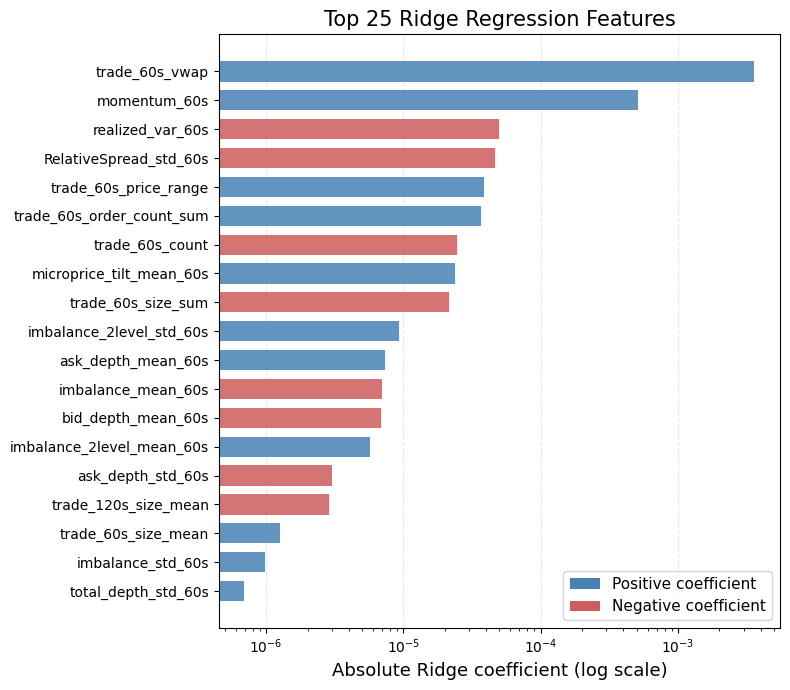

In [26]:

from matplotlib.patches import Patch

# Select top 25 by absolute coefficient
top25 = (
    importance_df
    .head(25)
    .sort_values("Abs_Coefficient", ascending=True)
    .copy()
)

# Log scale cannot display zero values
top25 = top25[top25["Abs_Coefficient"] > 0]

colors = np.where(
    top25["Coefficient"] >= 0,
    "steelblue",
    "indianred"
)

fig, ax = plt.subplots(figsize=(8, 7))

ax.barh(
    top25["Feature"],
    top25["Abs_Coefficient"],
    color=colors,
    height=0.7,
    alpha=0.85
)

ax.set_xscale("log")

ax.set_xlabel("Absolute Ridge coefficient (log scale)", fontsize=13)
ax.set_title("Top 25 Ridge Regression Features", fontsize=15)

ax.tick_params(axis="both", labelsize=10)

ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

legend_handles = [
    Patch(facecolor="steelblue", label="Positive coefficient"),
    Patch(facecolor="indianred", label="Negative coefficient")
]

ax.legend(
    handles=legend_handles,
    loc="lower right",
    fontsize=11,
    frameon=True
)

plt.tight_layout()
plt.show()

# Out-of-Fold Predictions and Model Performance Comparison

Out-of-fold (OOF) predictions are generated for each model using 10-fold grouped cross-validation to evaluate predictions across the entire training dataset.

- Generates an OOF prediction for every training observation using each model and the previously defined `GroupKFold` cross-validation scheme.
- Stores the actual target values alongside the OOF predictions from the Mean Baseline, Ridge Regression, Elastic Net, and XGBoost models.
- Displays the first five rows of the resulting prediction dataset.
- Calculates overall OOF RMSE and MAE for each model using predictions from all 10 validation folds.
- Sorts the models by overall OOF RMSE to compare their predictive performance.
- Determines common axis limits across actual and predicted values to ensure consistent scales across the plots.
- Generates separate actual-versus-predicted scatter plots for each model.
- Adds a diagonal reference line representing perfect predictions, allowing deviations from the ideal predictions to be visually assessed.

Generating OOF predictions: Mean Baseline
Generating OOF predictions: Ridge Regression_alpha1


[Parallel(n_jobs=1)]: Done  10 out of  10 | elapsed:    0.2s finished


Generating OOF predictions: Elastic Net


[Parallel(n_jobs=1)]: Done  10 out of  10 | elapsed:   14.8s finished


Generating OOF predictions: XGBoost


[Parallel(n_jobs=1)]: Done  10 out of  10 | elapsed:   14.7s finished
[Parallel(n_jobs=1)]: Done  10 out of  10 | elapsed:  2.5min finished



First five OOF predictions:
     Actual  Mean Baseline  Ridge Regression_alpha1  Elastic Net   XGBoost
0  1.000527       1.000002                 1.000324     1.000223  1.000215
1  0.997798       0.999985                 0.999812     0.999745  0.999741
2  0.997941       1.000009                 0.998398     0.998492  0.998435
3  0.999930       0.999985                 0.999552     0.999582  0.999562
4  0.997382       1.000002                 0.998365     0.998438  0.998309

OOF performance comparison:
                  Model     RMSE      MAE
Ridge Regression_alpha1 0.002521 0.001568
            Elastic Net 0.002535 0.001575
                XGBoost 0.002609 0.001586
          Mean Baseline 0.004506 0.002700


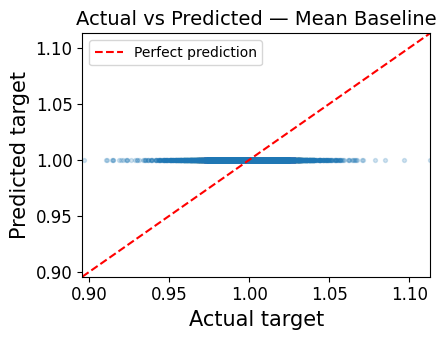

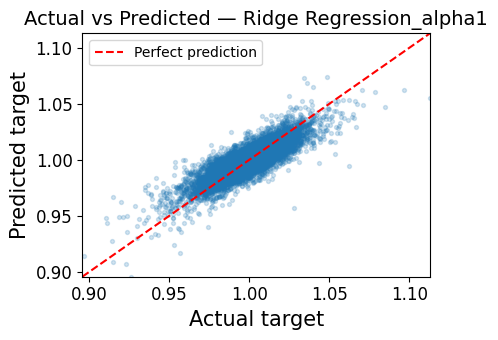

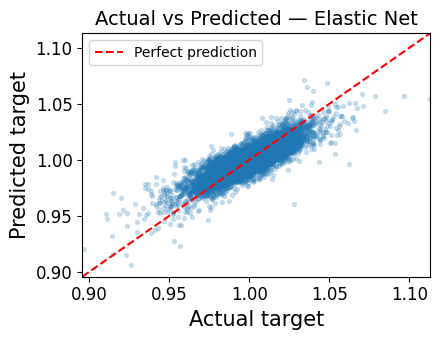

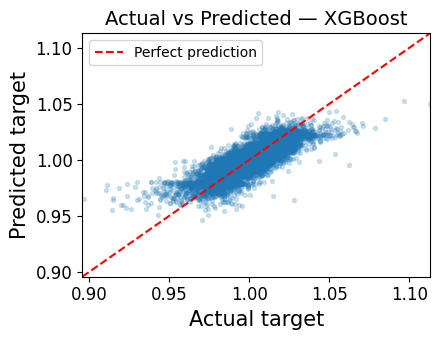

In [30]:

from sklearn.model_selection import cross_val_predict
from sklearn.metrics import root_mean_squared_error, mean_absolute_error

# 1. Generate out-of-fold predictions for every model
oof_predictions = pd.DataFrame({
    "Actual": np.asarray(y_train)
})

for name, model in models.items():

    print(f"Generating OOF predictions: {name}", flush=True)

    oof_predictions[name] = cross_val_predict(
        estimator=model,
        X=X_train_model,
        y=y_train,
        groups=groups,
        cv=cv,
        n_jobs=1,
        verbose=2
    )

# 2. Display the predictions
print("\nFirst five OOF predictions:")
print(oof_predictions.head())

# 3. Calculate overall OOF RMSE and MAE for every model
results = []

for name in models.keys():

    actual = oof_predictions["Actual"]
    predicted = oof_predictions[name]

    results.append({
        "Model": name,
        "RMSE": root_mean_squared_error(actual, predicted),
        "MAE": mean_absolute_error(actual, predicted)
    })

results_df = (
    pd.DataFrame(results)
    .sort_values("RMSE")
    .reset_index(drop=True)
)

print("\nOOF performance comparison:")
print(results_df.to_string(index=False))

# 4. Use common axis limits for fair visual comparison
all_values = oof_predictions[
    ["Actual"] + list(models.keys())
].to_numpy()

low = np.nanmin(all_values)
high = np.nanmax(all_values)

# 5. Plot Actual vs Predicted for every model
actual = oof_predictions["Actual"]

for model_name in models.keys():

    predicted = oof_predictions[model_name]

    plt.figure(figsize=(4.5, 3.5))

    plt.scatter(
        actual,
        predicted,
        alpha=0.2,
        s=8
    )

    # Perfect prediction line
    plt.plot(
        [low, high],
        [low, high],
        "--",
        color="red",
        label="Perfect prediction"
    )

    plt.xlim(low, high)
    plt.ylim(low, high)

    plt.xlabel("Actual target", fontsize=15)
    plt.ylabel("Predicted target", fontsize=15)
    plt.title(f"Actual vs Predicted — {model_name}", fontsize=14)

    plt.tick_params(axis="both", labelsize=12)
    plt.legend(fontsize=11)

    plt.legend()
    plt.tight_layout()
    plt.show()